
# Breast Cancer Image Classification Using Deep Learning

**CodeNova AI/ML Internship — Task 3**

This project explores breast ultrasound images and trains a deep-learning model to classify them as benign, malignant, or normal.

### Project workflow
1. Load and inspect a public dataset.
2. Explore the image classes and remove segmentation masks from classification inputs.
3. Split the data into training, validation, and test sets.
4. Train a transfer-learning model using MobileNetV2.
5. Evaluate the model using classification metrics and charts.
6. Test a separate image and save the trained model.

**Disclaimer:** Educational research only. This model is not intended for clinical diagnosis.


In [1]:

from pathlib import Path
import json
import random
import shutil

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
    auc
)
from sklearn.preprocessing import label_binarize

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

PROJECT_DIR = Path.cwd()
DATASET_DIR = PROJECT_DIR / "dataset"
MODEL_DIR = PROJECT_DIR / "models"
PLOT_DIR = PROJECT_DIR / "visualizations"

MODEL_DIR.mkdir(exist_ok=True)
PLOT_DIR.mkdir(exist_ok=True)

IMG_SIZE = (160, 160)
BATCH_SIZE = 16
EPOCHS = 12

print("TensorFlow version:", tf.__version__)
print("Project directory:", PROJECT_DIR)
print("Dataset directory:", DATASET_DIR)
print("GPU devices:", tf.config.list_physical_devices("GPU"))


TensorFlow version: 2.21.0
Project directory: c:\Users\telim\OneDrive\Desktop\Internships-Content\CodeNova\Task-3 Prediction Model\Breast Cancer Classification
Dataset directory: c:\Users\telim\OneDrive\Desktop\Internships-Content\CodeNova\Task-3 Prediction Model\Breast Cancer Classification\dataset
GPU devices: []


In [2]:

CLASS_NAMES = ["benign", "malignant", "normal"]
VALID_EXTENSIONS = {".png", ".jpg", ".jpeg", ".bmp"}

if not DATASET_DIR.exists():
    raise FileNotFoundError(
        f"Dataset folder not found: {DATASET_DIR}"
    )

image_records = []

for image_path in DATASET_DIR.rglob("*"):
    if not image_path.is_file():
        continue

    if image_path.suffix.lower() not in VALID_EXTENSIONS:
        continue

    # Classify by the parent directory name.
    class_name = image_path.parent.name.lower()

    if class_name not in CLASS_NAMES:
        continue

    # Never treat segmentation masks as input images.
    if "mask" in image_path.stem.lower():
        continue

    try:
        with Image.open(image_path) as img:
            img.verify()

        image_records.append({
            "path": str(image_path.resolve()),
            "label": class_name
        })

    except Exception:
        print("Skipping unreadable image:", image_path)

image_df = pd.DataFrame(image_records)

if image_df.empty:
    raise ValueError(
        "No valid images found. Check that dataset contains "
        "benign, malignant, and normal folders."
    )

found_classes = set(image_df["label"].unique())
missing_classes = set(CLASS_NAMES) - found_classes

if missing_classes:
    raise ValueError(
        f"Missing class folders or images: {sorted(missing_classes)}"
    )

print("Total original ultrasound images:", len(image_df))
print("Segmentation masks excluded.")
print("\nClass counts:")
display(image_df["label"].value_counts().reindex(CLASS_NAMES))
display(image_df.head())


Total original ultrasound images: 780
Segmentation masks excluded.

Class counts:


label
benign       437
malignant    210
normal       133
Name: count, dtype: int64

,path,label
0,C:\Users\telim\OneDrive\Desktop\Internships-Co...,benign
1,C:\Users\telim\OneDrive\Desktop\Internships-Co...,benign
2,C:\Users\telim\OneDrive\Desktop\Internships-Co...,benign
3,C:\Users\telim\OneDrive\Desktop\Internships-Co...,benign
4,C:\Users\telim\OneDrive\Desktop\Internships-Co...,benign


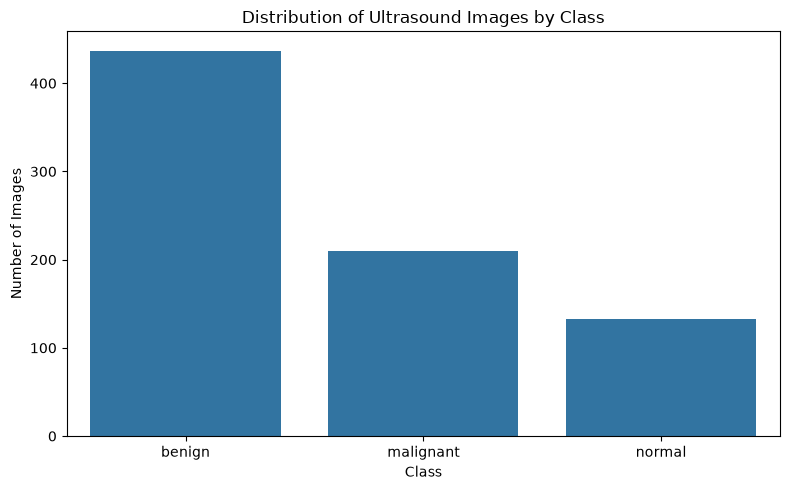

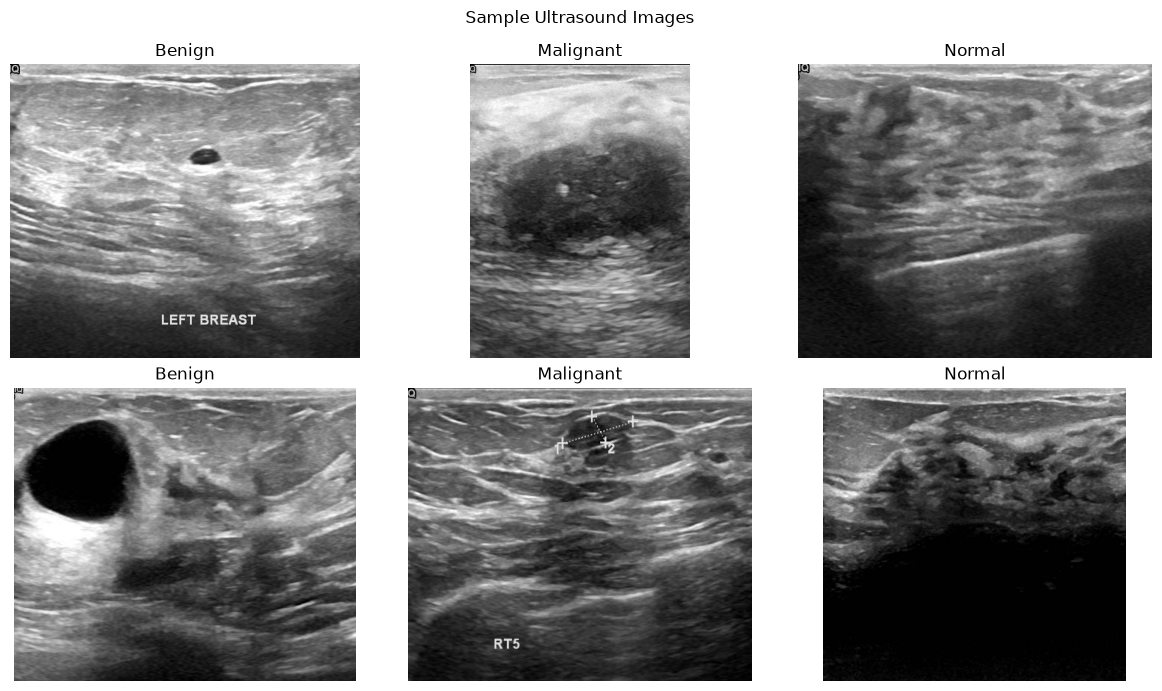

In [3]:

class_counts = (
    image_df["label"]
    .value_counts()
    .reindex(CLASS_NAMES, fill_value=0)
)

plt.figure(figsize=(8, 5))
sns.barplot(x=class_counts.index, y=class_counts.values)
plt.title("Distribution of Ultrasound Images by Class")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.tight_layout()
plt.savefig(PLOT_DIR / "class_distribution.png", dpi=150)
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(12, 7))

for col, class_name in enumerate(CLASS_NAMES):
    examples = image_df[image_df["label"] == class_name].head(2)

    for row in range(2):
        ax = axes[row, col]

        if row < len(examples):
            path = examples.iloc[row]["path"]
            with Image.open(path) as img:
                ax.imshow(img.convert("RGB"))

            ax.set_title(class_name.title())
        else:
            ax.set_visible(False)

        ax.axis("off")

plt.suptitle("Sample Ultrasound Images")
plt.tight_layout()
plt.savefig(PLOT_DIR / "sample_images.png", dpi=150)
plt.show()


In [4]:

train_df, temp_df = train_test_split(
    image_df,
    test_size=0.30,
    random_state=SEED,
    stratify=image_df["label"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_df["label"]
)

label_to_id = {name: i for i, name in enumerate(CLASS_NAMES)}
id_to_label = {i: name for name, i in label_to_id.items()}

for split_df in (train_df, val_df, test_df):
    split_df["label_id"] = split_df["label"].map(label_to_id)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

print("\nTraining distribution:")
display(train_df["label"].value_counts().reindex(CLASS_NAMES))

print("\nValidation distribution:")
display(val_df["label"].value_counts().reindex(CLASS_NAMES))

print("\nTest distribution:")
display(test_df["label"].value_counts().reindex(CLASS_NAMES))


Training images: 546
Validation images: 117
Testing images: 117

Training distribution:


label
benign       306
malignant    147
normal        93
Name: count, dtype: int64


Validation distribution:


label
benign       65
malignant    32
normal       20
Name: count, dtype: int64


Test distribution:


label
benign       66
malignant    31
normal       20
Name: count, dtype: int64

In [5]:

AUTOTUNE = tf.data.AUTOTUNE

def load_image(path, label):
    image_bytes = tf.io.read_file(path)

    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        IMG_SIZE
    )

    image = tf.cast(image, tf.float32)

    # MobileNetV2 expects pixels scaled to [-1, 1].
    image = tf.keras.applications.mobilenet_v2.preprocess_input(
        image
    )

    return image, label


def make_dataset(frame, training=False):
    paths = frame["path"].astype(str).values
    labels = frame["label_id"].astype("int32").values

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        ds = ds.shuffle(
            buffer_size=len(frame),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(AUTOTUNE)

    return ds


train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)

print("TensorFlow datasets are ready.")


TensorFlow datasets are ready.


In [6]:

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.10),
], name="data_augmentation")

base_model = tf.keras.applications.MobileNetV2(
    input_shape=(*IMG_SIZE, 3),
    include_top=False,
    weights="imagenet"
)

# Initially freeze pretrained layers.
base_model.trainable = False

inputs = tf.keras.Input(shape=(*IMG_SIZE, 3))

x = data_augmentation(inputs)

# Keep the pretrained backbone in inference mode.
x = base_model(x, training=False)

x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.30)(x)

outputs = tf.keras.layers.Dense(
    len(CLASS_NAMES),
    activation="softmax"
)(x)

model = tf.keras.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,261,827 (8.63 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [7]:

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(MODEL_DIR / "best_model.keras"),
        monitor="val_loss",
        save_best_only=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)


Epoch 1/12


c:\Users\telim\OneDrive\Desktop\Internships-Content\CodeNova\Task-3 Prediction Model\Breast Cancer Classification\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


35/35 ━━━━━━━━━━━━━━━━━━━━ 25s 458ms/step - accuracy: 0.5421 - loss: 1.1375 - val_accuracy: 0.6581 - val_loss: 0.7737 - learning_rate: 0.0010
Epoch 2/12
35/35 ━━━━━━━━━━━━━━━━━━━━ 12s 329ms/step - accuracy: 0.6044 - loss: 0.8478 - val_accuracy: 0.6838 - val_loss: 0.7522 - learning_rate: 0.0010
Epoch 3/12
35/35 ━━━━━━━━━━━━━━━━━━━━ 12s 331ms/step - accuracy: 0.6630 - loss: 0.7976 - val_accuracy: 0.7265 - val_loss: 0.6389 - learning_rate: 0.0010
Epoch 4/12
35/35 ━━━━━━━━━━━━━━━━━━━━ 10s 297ms/step - accuracy: 0.7033 - loss: 0.6742 - val_accuracy: 0.7521 - val_loss: 0.6027 - learning_rate: 0.0010
Epoch 5/12
35/35 ━━━━━━━━━━━━━━━━━━━━ 20s 287ms/step - accuracy: 0.7143 - loss: 0.6831 - val_accuracy: 0.7094 - val_loss: 0.6494 - learning_rate: 0.0010
Epoch 6/12
35/35 ━━━━━━━━━━━━━━━━━━━━ 10s 283ms/step - accuracy: 0.7601 - loss: 0.5772 - val_accuracy: 0.7436 - val_loss: 0.6103 - learning_rate: 0.0010
Epoch 7/12
35/35 ━━━━━━━━━━━━━━━━━━━━ 10s 275ms/step - accuracy: 0.7326 - loss: 0.6205 - val_

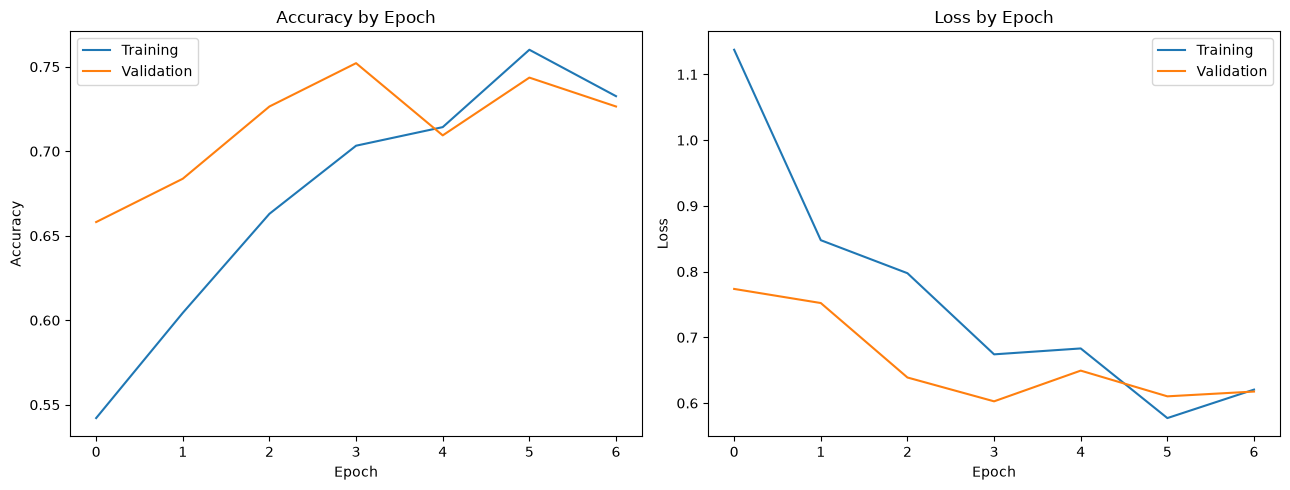

In [8]:

history_df = pd.DataFrame(history.history)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(history_df["accuracy"], label="Training")
axes[0].plot(history_df["val_accuracy"], label="Validation")
axes[0].set_title("Accuracy by Epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(history_df["loss"], label="Training")
axes[1].plot(history_df["val_loss"], label="Validation")
axes[1].set_title("Loss by Epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.savefig(PLOT_DIR / "training_curves.png", dpi=150)
plt.show()

history_df.to_csv(
    PLOT_DIR / "training_history.csv",
    index=False
)


In [9]:

# Reload the best checkpoint based on validation loss.
best_model = tf.keras.models.load_model(
    MODEL_DIR / "best_model.keras"
)

test_loss, test_accuracy = best_model.evaluate(test_ds, verbose=0)

y_true = test_df["label_id"].to_numpy()

probabilities = best_model.predict(test_ds, verbose=0)
y_pred = np.argmax(probabilities, axis=1)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Macro F1-score: {f1_score(y_true, y_pred, average='macro'):.4f}")
print(f"Macro precision: {precision_score(y_true, y_pred, average='macro', zero_division=0):.4f}")
print(f"Macro recall: {recall_score(y_true, y_pred, average='macro', zero_division=0):.4f}")

print("\nClassification report:")
print(
    classification_report(
        y_true,
        y_pred,
        labels=list(range(len(CLASS_NAMES))),
        target_names=CLASS_NAMES,
        zero_division=0
    )
)

report = classification_report(
    y_true,
    y_pred,
    labels=list(range(len(CLASS_NAMES))),
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0
)

pd.DataFrame(report).transpose().to_csv(
    PLOT_DIR / "classification_report.csv"
)


Test loss: 0.6035
Test accuracy: 0.7179
Macro F1-score: 0.7144
Macro precision: 0.7214
Macro recall: 0.7125

Classification report:
              precision    recall  f1-score   support

      benign       0.79      0.74      0.77        66
   malignant       0.54      0.65      0.59        31
      normal       0.83      0.75      0.79        20

    accuracy                           0.72       117
   macro avg       0.72      0.71      0.71       117
weighted avg       0.73      0.72      0.72       117



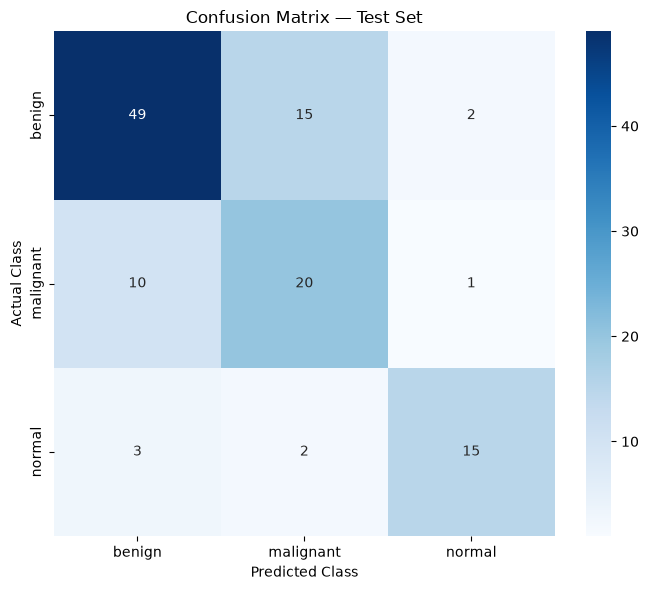

In [10]:

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(CLASS_NAMES)))
)

plt.figure(figsize=(7, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.title("Confusion Matrix — Test Set")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.savefig(PLOT_DIR / "confusion_matrix.png", dpi=150)
plt.show()


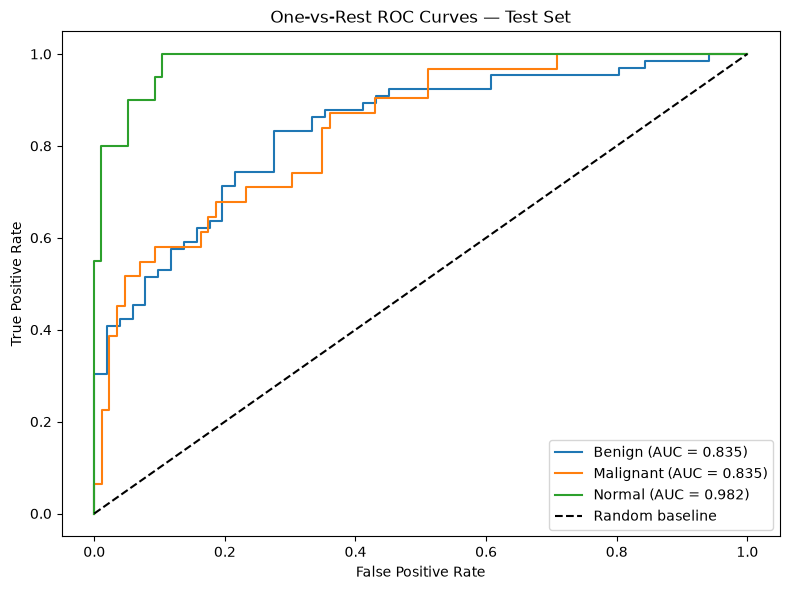

Per-class ROC-AUC: {'benign': 0.8354129530600118, 'malignant': 0.8345836459114778, 'normal': 0.9824742268041238}
Macro ROC-AUC: 0.8841569419252044


In [11]:

y_true_binary = label_binarize(
    y_true,
    classes=list(range(len(CLASS_NAMES)))
)

plt.figure(figsize=(8, 6))
auc_results = {}

for i, class_name in enumerate(CLASS_NAMES):
    # A ROC curve requires both positive and negative examples.
    if len(np.unique(y_true_binary[:, i])) < 2:
        print("Cannot calculate ROC curve for:", class_name)
        continue

    fpr, tpr, _ = roc_curve(
        y_true_binary[:, i],
        probabilities[:, i]
    )

    class_auc = auc(fpr, tpr)
    auc_results[class_name] = class_auc

    plt.plot(
        fpr,
        tpr,
        label=f"{class_name.title()} (AUC = {class_auc:.3f})"
    )

plt.plot([0, 1], [0, 1], "k--", label="Random baseline")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("One-vs-Rest ROC Curves — Test Set")
plt.legend()
plt.tight_layout()
plt.savefig(PLOT_DIR / "roc_curves.png", dpi=150)
plt.show()

print("Per-class ROC-AUC:", auc_results)

if len(np.unique(y_true)) > 1:
    print(
        "Macro ROC-AUC:",
        roc_auc_score(
            y_true,
            probabilities,
            multi_class="ovr",
            average="macro",
            labels=list(range(len(CLASS_NAMES)))
        )
    )


,Model,Accuracy,Macro F1
0,Majority-class baseline,0.564103,0.240437
1,MobileNetV2 transfer learning,0.717949,0.714445


<Figure size 800x500 with 0 Axes>

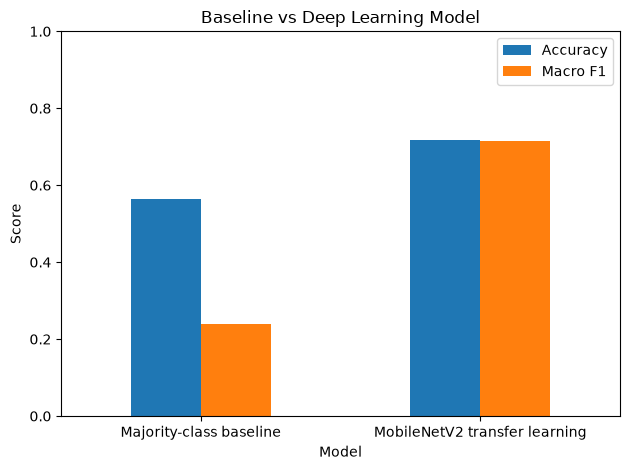

In [12]:

majority_class = int(
    train_df["label_id"].value_counts().idxmax()
)

baseline_predictions = np.full_like(
    y_true,
    fill_value=majority_class
)

comparison = pd.DataFrame([
    {
        "Model": "Majority-class baseline",
        "Accuracy": accuracy_score(y_true, baseline_predictions),
        "Macro F1": f1_score(
            y_true, baseline_predictions,
            average="macro", zero_division=0
        )
    },
    {
        "Model": "MobileNetV2 transfer learning",
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro F1": f1_score(
            y_true, y_pred,
            average="macro", zero_division=0
        )
    }
])

display(comparison)

comparison.to_csv(
    PLOT_DIR / "baseline_comparison.csv",
    index=False
)

plt.figure(figsize=(8, 5))
comparison.set_index("Model")[["Accuracy", "Macro F1"]].plot(
    kind="bar",
    ylim=(0, 1),
    rot=0
)
plt.title("Baseline vs Deep Learning Model")
plt.ylabel("Score")
plt.tight_layout()
plt.savefig(PLOT_DIR / "baseline_comparison.png", dpi=150)
plt.show()


In [13]:

FINAL_MODEL_PATH = MODEL_DIR / "breast_ultrasound_classifier.keras"

best_model.save(FINAL_MODEL_PATH)

with open(MODEL_DIR / "class_names.json", "w", encoding="utf-8") as file:
    json.dump(CLASS_NAMES, file, indent=4)

print("Saved model:", FINAL_MODEL_PATH)
print("Saved class labels:", MODEL_DIR / "class_names.json")


Saved model: c:\Users\telim\OneDrive\Desktop\Internships-Content\CodeNova\Task-3 Prediction Model\Breast Cancer Classification\models\breast_ultrasound_classifier.keras
Saved class labels: c:\Users\telim\OneDrive\Desktop\Internships-Content\CodeNova\Task-3 Prediction Model\Breast Cancer Classification\models\class_names.json


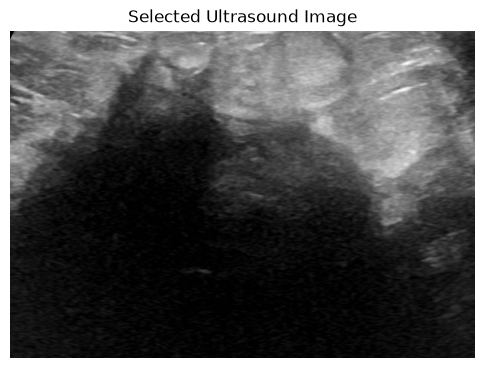

Predicted dataset class: malignant
Model confidence score: 88.18%

Scores for all classes:


,Class,Model score
1,malignant,0.881845
0,benign,0.116726
2,normal,0.001429



Educational output only — not a medical diagnosis.


In [14]:

import tkinter as tk
from tkinter import filedialog

root = tk.Tk()
root.withdraw()
root.attributes("-topmost", True)

selected_file = filedialog.askopenfilename(
    title="Select an ultrasound image",
    filetypes=[
        ("Image files", "*.png *.jpg *.jpeg *.bmp"),
        ("All files", "*.*")
    ]
)

root.destroy()

if selected_file:
    with Image.open(selected_file) as img:
        display_image = img.convert("RGB")
        plt.figure(figsize=(6, 5))
        plt.imshow(display_image)
        plt.axis("off")
        plt.title("Selected Ultrasound Image")
        plt.show()

    resized = display_image.resize(IMG_SIZE)
    image_array = np.asarray(resized, dtype=np.float32)
    image_array = tf.keras.applications.mobilenet_v2.preprocess_input(
        image_array
    )

    prediction_probabilities = best_model.predict(
        np.expand_dims(image_array, axis=0),
        verbose=0
    )[0]

    predicted_id = int(np.argmax(prediction_probabilities))
    predicted_class = CLASS_NAMES[predicted_id]
    confidence = float(prediction_probabilities[predicted_id])

    print("Predicted dataset class:", predicted_class)
    print(f"Model confidence score: {confidence:.2%}")

    print("\nScores for all classes:")
    display(
        pd.DataFrame({
            "Class": CLASS_NAMES,
            "Model score": prediction_probabilities
        }).sort_values("Model score", ascending=False)
    )

    print(
        "\nEducational output only — not a medical diagnosis."
    )
else:
    print("No image selected. You can run this cell again to test an image.")


In [15]:

import io
import ipywidgets as widgets
from IPython.display import display, clear_output

# Image upload control inside the notebook
image_upload = widgets.FileUpload(
    accept=".png,.jpg,.jpeg,.bmp",
    multiple=False,
    description="Choose image"
)

predict_button = widgets.Button(
    description="Classify Image",
    button_style="primary",
    icon="search"
)

output = widgets.Output()

def classify_uploaded_image(_):
    with output:
        clear_output(wait=True)

        if not image_upload.value:
            print("Please upload an ultrasound image first.")
            return

        # Handle current ipywidgets upload format
        uploaded = image_upload.value

        if isinstance(uploaded, dict):
            file_info = next(iter(uploaded.values()))
        else:
            file_info = uploaded[0]

        image_bytes = file_info["content"]

        try:
            with Image.open(io.BytesIO(image_bytes)) as img:
                display_image = img.convert("RGB")

            plt.figure(figsize=(6, 5))
            plt.imshow(display_image)
            plt.axis("off")
            plt.title("Uploaded Ultrasound Image")
            plt.show()

            resized = display_image.resize(IMG_SIZE)

            image_array = np.asarray(
                resized, dtype=np.float32
            )

            image_array = (
                tf.keras.applications.mobilenet_v2
                .preprocess_input(image_array)
            )

            prediction_probabilities = best_model.predict(
                np.expand_dims(image_array, axis=0),
                verbose=0
            )[0]

            predicted_id = int(
                np.argmax(prediction_probabilities)
            )

            predicted_class = CLASS_NAMES[predicted_id]
            confidence = float(
                prediction_probabilities[predicted_id]
            )

            print("Predicted dataset class:", predicted_class)
            print(f"Model confidence score: {confidence:.2%}")

            results_df = pd.DataFrame({
                "Class": CLASS_NAMES,
                "Model score": prediction_probabilities
            }).sort_values(
                "Model score", ascending=False
            )

            display(results_df)

            print(
                "\nEducational output only — "
                "not a medical diagnosis."
            )

        except Exception as error:
            print("Could not process this image:", error)

predict_button.on_click(classify_uploaded_image)

display(
    widgets.VBox([
        widgets.HTML(
            "<h3>Breast Ultrasound Image Classifier</h3>"
            "<p>Upload an image to view the model prediction.</p>"
        ),
        image_upload,
        predict_button,
        output
    ])
)
